# 01 EDA: IBM AML transactions (HI-Small)

**Goal:** understand the data well enough to choose a train, validation and test split and a first feature set.

**Dataset:** IBM Transactions for Anti Money Laundering, HI-Small variant (Altman et al., NeurIPS 2023). Synthetic data. Files live in `data/` and are not committed.

**Questions this notebook answers**
1. How many transactions are there, and how rare is laundering?
2. How is the data spread over time, and is any period unusable?
3. Which columns separate laundering too easily (shortcuts)?
4. What do amounts, currencies and self transfers look like?
5. How active are accounts, and do the accounts file and the transactions join cleanly?
6. What does the patterns file contain, and how much laundering does it cover?
7. Which split follows from all of this?

Each section ends with a short **Finding** to fill in after running the cells.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data")
TRANS_FILE = DATA / "HI-Small_Trans.csv"
ACCOUNTS_FILE = DATA / "HI-Small_accounts.csv"
PATTERNS_FILE = DATA / "HI-Small_Patterns.txt"

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Load and schema

The raw header has two columns both called `Account`, so the columns are renamed on load. Bank IDs are read as integers because the file pads them with leading zeros inconsistently (for example `010`), and the accounts file stores them without padding.

In [2]:
TX_COLS = [
    "timestamp", "from_bank", "from_account", "to_bank", "to_account",
    "amount_received", "receiving_currency", "amount_paid",
    "payment_currency", "payment_format", "is_laundering",
]
TX_DTYPES = {
    "from_bank": "int32", "from_account": "category",
    "to_bank": "int32", "to_account": "category",
    "amount_received": "float64", "receiving_currency": "category",
    "amount_paid": "float64", "payment_currency": "category",
    "payment_format": "category", "is_laundering": "int8",
}

tx = pd.read_csv(TRANS_FILE, header=0, names=TX_COLS, dtype=TX_DTYPES)
tx["timestamp"] = pd.to_datetime(tx["timestamp"], format="%Y/%m/%d %H:%M")
tx["date"] = tx["timestamp"].dt.normalize()

print(f"rows: {len(tx):,}")
print(f"memory: {tx.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
tx.head()

rows: 5,078,345
memory: 351 MB


,timestamp,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering,date
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,"3,697.3400",US Dollar,"3,697.3400",US Dollar,Reinvestment,0,2022-09-01
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.0100,US Dollar,0.0100,US Dollar,Cheque,0,2022-09-01
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,"14,675.5700",US Dollar,"14,675.5700",US Dollar,Reinvestment,0,2022-09-01
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,"2,806.9700",US Dollar,"2,806.9700",US Dollar,Reinvestment,0,2022-09-01
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,"36,682.9700",US Dollar,"36,682.9700",US Dollar,Reinvestment,0,2022-09-01


In [3]:
print(tx.dtypes)
print()
print("missing values per column:")
print(tx.isna().sum())
print()
print("exact duplicate rows:", f"{tx.duplicated().sum():,}")

timestamp             datetime64[ns]
from_bank                      int32
from_account                category
to_bank                        int32
to_account                  category
amount_received              float64
receiving_currency          category
amount_paid                  float64
payment_currency            category
payment_format              category
is_laundering                   int8
date                  datetime64[ns]
dtype: object

missing values per column:
timestamp             0
from_bank             0
from_account          0
to_bank               0
to_account            0
amount_received       0
receiving_currency    0
amount_paid           0
payment_currency      0
payment_format        0
is_laundering         0
date                  0
dtype: int64

exact duplicate rows: 9


**Finding:** _fill in_

## 2. Label balance

In [4]:
n_pos = int(tx["is_laundering"].sum())
print(f"laundering rows: {n_pos:,} of {len(tx):,} ({n_pos / len(tx):.4%})")
print(f"one laundering row per {len(tx) / n_pos:,.0f} transactions")

laundering rows: 5,177 of 5,078,345 (0.1019%)
one laundering row per 981 transactions


With a positive rate this low, accuracy and ROC-AUC say very little. PR-AUC and recall at a fixed false positive rate are the metrics to use.

**Finding:** _fill in_

## 3. Time structure

A time based split needs to know how rows and laundering are spread across days.

In [5]:
daily = (
    tx.groupby("date")["is_laundering"]
    .agg(rows="size", laundering="sum")
    .assign(rate=lambda d: d["laundering"] / d["rows"])
)
daily

,rows,laundering,rate
date,,,
2022-09-01,1114921,322,0.0003
2022-09-02,754449,408,0.0005
2022-09-03,207382,391,0.0019
2022-09-04,207430,407,0.0020
2022-09-05,482650,471,0.0010
2022-09-06,482089,531,0.0011
2022-09-07,482751,497,0.0010
2022-09-08,482773,539,0.0011
2022-09-09,654467,514,0.0008


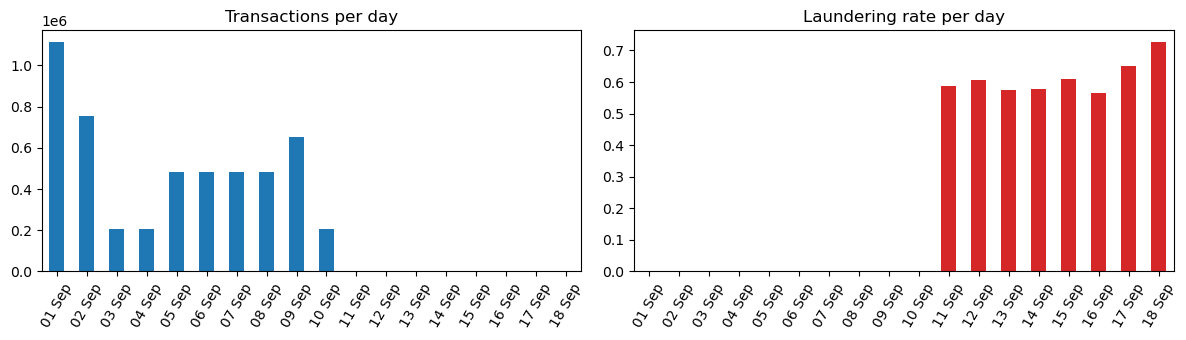

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
daily["rows"].plot.bar(ax=axes[0], title="Transactions per day")
daily["rate"].plot.bar(ax=axes[1], title="Laundering rate per day", color="tab:red")
for ax in axes:
    ax.set_xticklabels([d.strftime("%d %b") for d in daily.index], rotation=60)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [7]:
hourly = (
    tx.assign(hour=tx["timestamp"].dt.hour)
    .groupby("hour")["is_laundering"]
    .agg(rows="size", laundering="sum")
    .assign(rate=lambda d: d["laundering"] / d["rows"])
)
hourly

,rows,laundering,rate
hour,,,
0,634726,176,0.0003
1,193728,152,0.0008
2,193143,165,0.0009
3,193249,146,0.0008
4,193166,154,0.0008
5,193900,188,0.0010
6,194456,207,0.0011
7,193336,195,0.0010
8,192921,258,0.0013


Things to look for:
- Do the last days hold very few rows with a very high laundering rate? If so they cannot be an ordinary test set.
- Is the first day inflated by simulation start up?
- Is there a weekday and weekend pattern?

**Finding:** _fill in_

## 4. Payment format

Checked early because a categorical column that almost defines the label acts as a shortcut.

In [ ]:
by_format = (
    tx.groupby("payment_format", observed=True)["is_laundering"]
    .agg(rows="size", laundering="sum")
    .assign(
        rate=lambda d: d["laundering"] / d["rows"],
        share_of_laundering=lambda d: d["laundering"] / d["laundering"].sum(),
    )
    .sort_values("laundering", ascending=False)
)
by_format

If one format carries most laundering, every model must be reported with and without this column.

**Finding:** _fill in_

## 5. Currencies

In [ ]:
tx["cross_currency"] = tx["receiving_currency"].astype(str) != tx["payment_currency"].astype(str)

print(
    tx.groupby("cross_currency")["is_laundering"]
    .agg(rows="size", laundering="sum")
    .assign(rate=lambda d: d["laundering"] / d["rows"])
)

by_currency = (
    tx.groupby("payment_currency", observed=True)["is_laundering"]
    .agg(rows="size", laundering="sum")
    .assign(rate=lambda d: d["laundering"] / d["rows"])
    .sort_values("rows", ascending=False)
)
by_currency

**Finding:** _fill in_

## 6. Amounts

Amounts are in different currencies, so raw values are not comparable across rows. This section looks at the shape only.

In [ ]:
print(tx.groupby("is_laundering")["amount_paid"].describe(percentiles=[0.5, 0.9, 0.99]).T)
print()
same_amount = (tx["amount_paid"] == tx["amount_received"]).mean()
print(f"rows where amount paid equals amount received: {same_amount:.2%}")

In [ ]:
import numpy as np

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(-2, 10, 60)
for label, name in [(0, "normal"), (1, "laundering")]:
    values = np.log10(tx.loc[tx["is_laundering"] == label, "amount_paid"].clip(lower=0.01))
    ax.hist(values, bins=bins, density=True, alpha=0.5, label=name)
ax.set_xlabel("log10(amount paid)")
ax.set_title("Amount distribution by label")
ax.legend()
plt.show()

**Finding:** _fill in_

## 7. Self transfers

Rows where the sending and receiving account are the same.

In [ ]:
tx["self_transfer"] = (
    (tx["from_account"].astype(str) == tx["to_account"].astype(str))
    & (tx["from_bank"] == tx["to_bank"])
)
print(f"self transfers: {tx['self_transfer'].sum():,} ({tx['self_transfer'].mean():.2%})")
print()
print(
    tx.groupby("self_transfer")["is_laundering"]
    .agg(rows="size", laundering="sum")
)
print()
print(pd.crosstab(tx["payment_format"], tx["self_transfer"]))

Decide here whether self transfers stay in the training data, become a feature, or are dropped.

**Finding:** _fill in_

## 8. Account activity

Laundering in this dataset is built from multi-hop structures, so how connected an account is should matter.

In [ ]:
out_deg = tx.groupby("from_account", observed=True).size().rename("out_tx")
in_deg = tx.groupby("to_account", observed=True).size().rename("in_tx")
activity = pd.concat([out_deg, in_deg], axis=1).fillna(0).astype(int)

print(f"accounts seen in transactions: {len(activity):,}")
print(activity.describe(percentiles=[0.5, 0.9, 0.99]).T)

In [ ]:
laundering_accounts = pd.unique(
    pd.concat([
        tx.loc[tx["is_laundering"] == 1, "from_account"].astype(str),
        tx.loc[tx["is_laundering"] == 1, "to_account"].astype(str),
    ])
)
activity["touches_laundering"] = activity.index.astype(str).isin(laundering_accounts)

print(f"accounts touching at least one laundering row: {activity['touches_laundering'].sum():,}")
print()
print(activity.groupby("touches_laundering")[["out_tx", "in_tx"]].median())

Note for feature work: any per account count used as a model feature must be computed only from transactions earlier than the row being scored. The totals above use the whole period and are for description only.

**Finding:** _fill in_

## 9. Accounts file

Accounts are matched on bank ID and account number together, because a few account numbers appear under more than one bank.

In [ ]:
accounts = pd.read_csv(ACCOUNTS_FILE)
accounts.columns = ["bank_name", "bank_id", "account", "entity_id", "entity_name"]

print(f"rows: {len(accounts):,}")
print(f"unique accounts: {accounts['account'].nunique():,}")
print(f"unique entities: {accounts['entity_id'].nunique():,}")
print(f"unique banks: {accounts['bank_id'].nunique():,}")
print(f"account numbers listed more than once: {accounts['account'].duplicated().sum():,}")
accounts.head()

In [ ]:
accounts["entity_type"] = accounts["entity_name"].str.replace(r"\s*#\d+$", "", regex=True)
accounts["bank_group"] = accounts["bank_name"].str.replace(r"\s*#\d+$", "", regex=True)

print(accounts["entity_type"].value_counts())
print()
print(accounts["bank_group"].value_counts().head(15))

In [ ]:
tx_accounts = pd.concat([
    tx[["from_bank", "from_account"]].set_axis(["bank_id", "account"], axis=1),
    tx[["to_bank", "to_account"]].set_axis(["bank_id", "account"], axis=1),
]).astype({"account": str}).drop_duplicates()

joined = tx_accounts.merge(
    accounts[["bank_id", "account"]].drop_duplicates(),
    on=["bank_id", "account"], how="left", indicator=True,
)
print(f"distinct (bank, account) pairs in transactions: {len(tx_accounts):,}")
print(f"found in accounts file: {(joined['_merge'] == 'both').mean():.2%}")

The join coverage decides whether the agent tools can rely on the accounts file for every account they see.

**Finding:** _fill in_

## 10. Patterns file

Each block is one laundering attempt with a named typology. This is the source for the agent evaluation cases and for error analysis by typology.

In [ ]:
def parse_patterns(path):
    rows, attempt_id, typology = [], -1, None
    with open(path, encoding="utf-8") as handle:
        for line in handle:
            line = line.strip()
            if line.startswith("BEGIN LAUNDERING ATTEMPT"):
                attempt_id += 1
                typology = line.split(" - ", 1)[1].split(":")[0].strip()
            elif line and not line.startswith("END LAUNDERING ATTEMPT"):
                rows.append(line.split(",") + [attempt_id, typology])
    return pd.DataFrame(rows, columns=TX_COLS + ["attempt_id", "typology"])


patterns = parse_patterns(PATTERNS_FILE)
patterns["amount_paid"] = patterns["amount_paid"].astype(float)

print(f"attempts: {patterns['attempt_id'].nunique():,}")
print(f"transactions inside attempts: {len(patterns):,}")
print(f"share of all laundering rows: {len(patterns) / n_pos:.1%}")

In [ ]:
per_attempt = patterns.groupby(["typology", "attempt_id"]).size().rename("n_tx").reset_index()
(
    per_attempt.groupby("typology")["n_tx"]
    .agg(attempts="size", median_tx="median", max_tx="max", total_tx="sum")
    .sort_values("attempts", ascending=False)
)

In [ ]:
print(patterns["payment_format"].value_counts())
print()
print("is_laundering values inside patterns:", patterns["is_laundering"].unique())

Laundering rows that are in no pattern form a second group. Error analysis should report recall for both groups.

**Finding:** _fill in_

## 11. Proposed split

The proposal below keeps the split inside the dense period and holds the sparse tail apart. Adjust the dates if section 3 shows something different.

In [ ]:
SPLITS = {
    "train": ("2022-09-01", "2022-09-06"),
    "validation": ("2022-09-07", "2022-09-08"),
    "test": ("2022-09-09", "2022-09-10"),
    "tail (held apart)": ("2022-09-11", "2022-09-18"),
}

rows = []
for name, (start, end) in SPLITS.items():
    part = tx[(tx["date"] >= start) & (tx["date"] <= end)]
    rows.append({
        "split": name, "from": start, "to": end,
        "rows": len(part), "share_of_rows": len(part) / len(tx),
        "laundering": int(part["is_laundering"].sum()),
        "rate": part["is_laundering"].mean(),
    })
pd.DataFrame(rows).set_index("split")

## 12. Summary and decisions

Fill this in once the notebook has run. It becomes the opening of `docs/MODELLING.md`.

| Question | Answer |
|---|---|
| Rows and laundering rate | |
| Usable date range | |
| Shortcut columns | |
| Treatment of self transfers | |
| Accounts join coverage | |
| Final split | |
| First feature set | |

**Open questions for the modelling notebook:**
- _fill in_